# 02 - results analysis

Digging into `results/benchmark/episodes.csv` (written by `evaluate.py`) a bit more than the leaderboard does.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from evals.leaderboard import family, normalized_scores, overall_table, paired_comparison

df = pd.read_csv("../results/benchmark/episodes.csv", keep_default_na=False, na_values=[""])
print(df.shape, "episodes:", df.episode.nunique(), "agents:", list(df.agent.unique()))
overall_table(df).round(1)

(1890, 52) episodes: 30 agents: ['random', 'rule_based', 'fcfs', 'greedy', 'forecast', 'ppo_s0', 'ppo_s1', 'ppo_s2', 'a2c']


scenario,normal,peak_season,supply_shortage,transport_disruption,warehouse_failure,multi_warehouse,compound_crisis,norm_score,avg_rank
agent,,,,,,,,,
ppo_s1,80.0,91.4,47.7,74.7,74.2,79.2,65.0,117.3,1.4
ppo (mean of 3 seeds),79.5,91.3,46.9,74.5,73.2,77.8,64.9,116.2,NaN
ppo_s2,79.0,90.7,46.6,73.9,72.5,78.1,66.2,115.8,2.4
ppo_s0,79.6,91.6,46.5,74.8,73.0,76.1,63.6,115.5,2.1
a2c,71.3,73.8,36.2,68.8,66.0,72.9,52.1,102.5,4.6
forecast,70.1,76.0,35.6,65.5,64.5,68.6,53.3,100.0,4.9
rule_based,69.6,67.1,38.2,65.2,53.7,67.8,53.0,96.0,5.6
fcfs,69.3,57.5,34.5,61.2,53.4,67.5,44.2,91.4,7.0
greedy,45.6,-10.4,-7.0,33.1,41.1,42.8,-17.2,40.4,8.0


## Paired comparison against the forecast heuristic

Every agent saw the same seeds, so the per-seed difference removes most of the episode-to-episode noise
(a hard episode is hard for everyone).

In [2]:
ppo_seeds = [a for a in df.agent.unique() if family(a) == "ppo"]
for title, a in [("ppo (mean of seeds)", ppo_seeds), ("a2c", "a2c"), ("rule_based", "rule_based")]:
    comp = paired_comparison(df, a, "forecast")
    comp[["mean_diff", "ci95"]] = (comp[["mean_diff", "ci95"]] / 1000).round(2)
    print(f"--- {title} - forecast ($1000 per episode)")
    print(comp.to_string(index=False))

--- ppo (mean of seeds) - forecast ($1000 per episode)
            scenario  mean_diff  ci95  win_rate  episodes
     compound_crisis      11.61  1.55       1.0        30
     multi_warehouse       9.24  0.58       1.0        30
              normal       9.49  0.40       1.0        30
         peak_season      15.23  1.42       1.0        30
     supply_shortage      11.37  1.10       1.0        30
transport_disruption       8.95  0.48       1.0        30
   warehouse_failure       8.71  0.44       1.0        30
--- a2c - forecast ($1000 per episode)
            scenario  mean_diff  ci95  win_rate  episodes
     compound_crisis      -1.22  1.85  0.366667        30
     multi_warehouse       4.31  0.97  0.933333        30
              normal       1.29  1.02  0.600000        30
         peak_season      -2.22  1.66  0.300000        30
     supply_shortage       0.62  1.07  0.633333        30
transport_disruption       3.25  0.59  0.966667        30
   warehouse_failure       1.50  0.8

How much does pairing actually buy? Compare the spread of the per-episode difference with what you'd get
comparing two independent averages (sd of the difference = sqrt(var_a + var_b)).

In [3]:
piv = df.pivot_table(index=["scenario", "seed"], columns="agent", values="score")
rows = []
for a in piv.columns.drop("forecast"):
    unpaired = np.sqrt(piv[a].groupby(level=0).var() + piv["forecast"].groupby(level=0).var())
    paired = (piv[a] - piv["forecast"]).groupby(level=0).std()
    rows.append({"agent": a, "unpaired_sd": unpaired.mean(), "paired_sd": paired.mean(),
                 "ratio": (paired / unpaired).mean()})
pd.DataFrame(rows).set_index("agent").round(2)

,unpaired_sd,paired_sd,ratio
agent,,,
a2c,4772.88,3062.81,0.68
fcfs,5114.68,2053.89,0.42
greedy,6736.82,6302.73,0.98
ppo_s0,4715.66,2530.71,0.54
ppo_s1,4625.04,2516.23,0.53
ppo_s2,4694.87,2523.63,0.52
random,12387.86,12323.34,1.01
rule_based,5118.39,1888.36,0.39


Pairing roughly halves the noise for PPO and the heuristics (their results move together: a hard episode is
hard for everyone). For random / greedy it does nothing, their scores are basically uncorrelated with the
forecast heuristic's.

## Service vs. cost

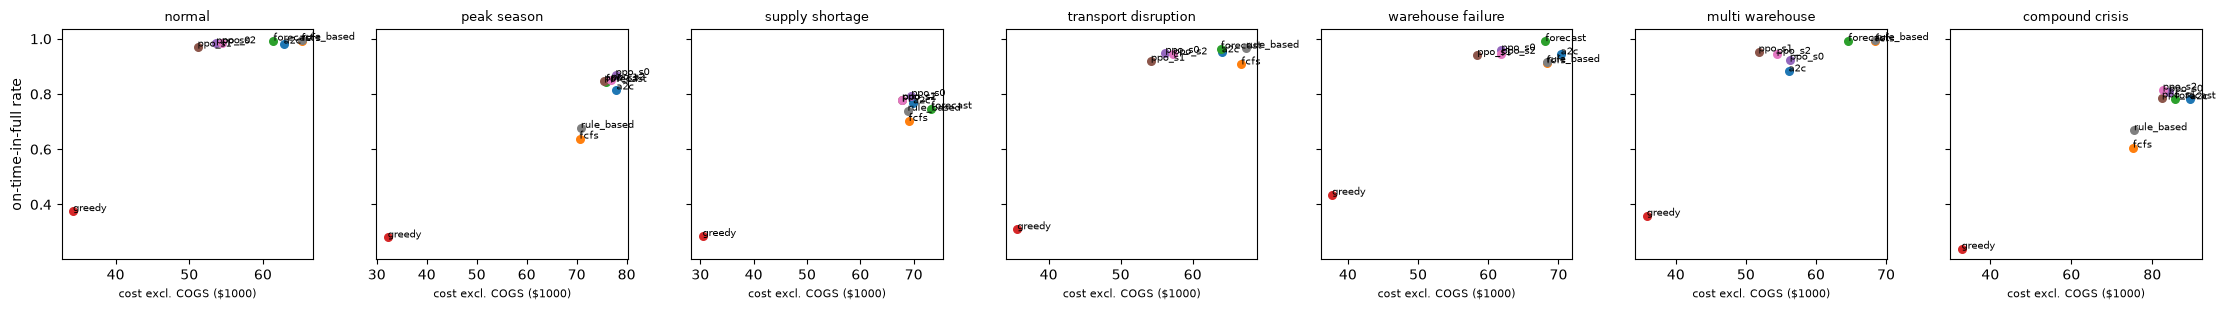

In [4]:
df["controllable_cost"] = (df.holding_cost + df.shipping_cost + df.inbound_freight + df.waste_cost
                           + df.production_cost - df.cogs)
agg = df.groupby(["scenario", "agent"])[["controllable_cost", "fill_rate", "otif_rate"]].mean().reset_index()
scen = list(dict.fromkeys(df.scenario))
fig, axes = plt.subplots(1, len(scen), figsize=(3.2 * len(scen), 3.2), sharey=True)
for ax, s in zip(axes, scen):
    sub = agg[(agg.scenario == s) & (agg.agent != "random")]
    for _, r in sub.iterrows():
        ax.scatter(r.controllable_cost / 1000, r.otif_rate, s=30)
        ax.annotate(r.agent, (r.controllable_cost / 1000, r.otif_rate), fontsize=7)
    ax.set_title(s.replace("_", " "), fontsize=9)
    ax.set_xlabel("cost excl. COGS ($1000)", fontsize=8)
axes[0].set_ylabel("on-time-in-full rate")
plt.tight_layout()
plt.show()

(`production_cost - cogs` is shift costs plus the purchase cost of goods that weren't sold yet, so it's a
rough "how much did we spend beyond what we sold" number.)

## What do the policies actually do?

In [5]:
beh = [c for c in df.columns if c.startswith("share_")] + ["ordered_units_per_day"]
df.groupby(["scenario", "agent"])[beh].mean().loc[(slice(None), ppo_seeds[:1] + ["a2c", "forecast", "rule_based"]), :].round(2)

,,share_priority_days,share_flexible_days,share_smart_days,share_express_days,share_expedite_days,share_double_shift,share_line_off,ordered_units_per_day
scenario,agent,,,,,,,,
compound_crisis,ppo_s0,0.72,0.30,0.68,0.14,0.38,0.79,0.00,269.00
multi_warehouse,ppo_s0,0.91,0.23,0.93,0.01,0.00,0.20,0.00,224.59
normal,ppo_s0,0.71,0.14,0.71,0.01,0.00,0.18,0.00,225.23
peak_season,ppo_s0,0.74,0.24,0.82,0.03,0.27,0.78,0.00,293.27
supply_shortage,ppo_s0,0.81,0.48,0.37,0.44,0.33,0.63,0.00,215.00
transport_disruption,ppo_s0,0.78,0.25,0.78,0.03,0.00,0.18,0.00,225.03
warehouse_failure,ppo_s0,0.84,0.34,0.57,0.23,0.00,0.21,0.00,231.95
compound_crisis,a2c,0.78,0.61,0.68,0.23,0.44,0.84,0.00,261.58
multi_warehouse,a2c,0.15,0.19,0.13,0.05,0.00,0.18,0.00,220.37
